# Tech Challenge FIAP - Modelo opcional de risco de insatisfação

O objetivo é verificar se dados disponíveis ao longo da jornada ajudam a priorizar clientes com `nps_score < 7`.
O modelo é um protótipo retrospectivo e não substitui a pesquisa de satisfação.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix,
    precision_score, recall_score, roc_auc_score, RocCurveDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv(Path("../Banco_de_dados/Base_NPS.csv"))
df["detrator_operacional"] = (df["nps_score"] < 7).astype(int)
print(df.shape)
print(df["detrator_operacional"].value_counts(normalize=True).sort_index().round(4))

(2500, 20)
detrator_operacional
0    0.1564
1    0.8436
Name: proportion, dtype: float64


Foram excluídos os identificadores, a nota usada para criar a variável-alvo, a recompra em 30 dias e o CSAT interno. As duas últimas variáveis têm risco de usar informações conhecidas somente depois da experiência.

In [3]:
cliente_pedido = [
    "customer_age", "customer_region", "customer_tenure_months",
    "order_value", "items_quantity", "discount_value",
    "payment_installments", "delivery_time_days", "freight_value",
]
logistica = cliente_pedido + ["delivery_delay_days", "delivery_attempts"]
completo = logistica + [
    "customer_service_contacts", "resolution_time_days", "complaints_count",
]
grupos = {
    "Cliente + pedido": cliente_pedido,
    "+ Logística": logistica,
    "+ Atendimento": completo,
}

In [4]:
indices = np.arange(len(df))
y = df["detrator_operacional"]
idx_treino, idx_teste = train_test_split(
    indices, test_size=0.25, random_state=42, stratify=y
)
print("Treino:", len(idx_treino), "| Teste:", len(idx_teste))

Treino: 1875 | Teste: 625


In [5]:
def criar_regressao_logistica(colunas):
    numericas = [coluna for coluna in colunas if coluna != "customer_region"]
    preparacao = ColumnTransformer([
        ("numericas", StandardScaler(), numericas),
        ("regiao", OneHotEncoder(handle_unknown="ignore"), ["customer_region"]),
    ])
    return Pipeline([
        ("preparacao", preparacao),
        ("modelo", LogisticRegression(
            class_weight="balanced", max_iter=1000, random_state=42
        )),
    ])


def avaliar(modelo, colunas, dados=df, alvo=y, treino=idx_treino, teste=idx_teste):
    modelo.fit(dados.iloc[treino][colunas], alvo.iloc[treino])
    previsto = modelo.predict(dados.iloc[teste][colunas])
    score = modelo.predict_proba(dados.iloc[teste][colunas])[:, 1]
    return {
        "ROC AUC": roc_auc_score(alvo.iloc[teste], score),
        "Balanced Accuracy": balanced_accuracy_score(alvo.iloc[teste], previsto),
        "Acurácia": accuracy_score(alvo.iloc[teste], previsto),
        "Recall detratores": recall_score(alvo.iloc[teste], previsto),
        "Precisão detratores": precision_score(alvo.iloc[teste], previsto),
    }, previsto, score

In [6]:
modelos = {}
resultados = {}
for nome, colunas in grupos.items():
    modelos[nome] = criar_regressao_logistica(colunas)
    resultados[nome], _, _ = avaliar(modelos[nome], colunas)

pd.DataFrame(resultados).T.round(3)

,ROC AUC,Balanced Accuracy,Acurácia,Recall detratores,Precisão detratores
Cliente + pedido,0.507,0.518,0.558,0.577,0.852
+ Logística,0.798,0.739,0.722,0.713,0.942
+ Atendimento,0.885,0.786,0.806,0.816,0.947


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultado_cv = {}
for nome, colunas in grupos.items():
    scores = cross_val_score(
        criar_regressao_logistica(colunas),
        df.iloc[idx_treino][colunas],
        y.iloc[idx_treino],
        cv=cv,
        scoring="roc_auc",
    )
    resultado_cv[nome] = {"média": scores.mean(), "desvio": scores.std()}

pd.DataFrame(resultado_cv).T.round(3)

,média,desvio
Cliente + pedido,0.473,0.034
+ Logística,0.799,0.023
+ Atendimento,0.888,0.013


## Avaliação do modelo completo

In [8]:
modelo_principal = modelos["+ Atendimento"]
metricas_principais, previsto, score = avaliar(modelo_principal, completo)
matriz = confusion_matrix(y.iloc[idx_teste], previsto)
print(pd.Series(metricas_principais).round(3))
print()
print("Matriz de confusão:")
print(matriz)

ROC AUC                0.885
Balanced Accuracy      0.786
Acurácia               0.806
Recall detratores      0.816
Precisão detratores    0.947
dtype: float64

Matriz de confusão:
[[ 74  24]
 [ 97 430]]


In [9]:
baseline = np.ones(len(idx_teste), dtype=int)
pd.Series({
    "Acurácia": accuracy_score(y.iloc[idx_teste], baseline),
    "Balanced Accuracy": balanced_accuracy_score(y.iloc[idx_teste], baseline),
    "Recall detratores": recall_score(y.iloc[idx_teste], baseline),
    "Precisão detratores": precision_score(y.iloc[idx_teste], baseline),
}).round(3)

Acurácia               0.843
Balanced Accuracy      0.500
Recall detratores      1.000
Precisão detratores    0.843
dtype: float64

In [10]:
nomes = modelo_principal.named_steps["preparacao"].get_feature_names_out()
coeficientes = pd.Series(
    modelo_principal.named_steps["modelo"].coef_[0], index=nomes
).sort_values(key=np.abs, ascending=False)
coeficientes.head(10).round(3)

numericas__delivery_delay_days          1.709
numericas__complaints_count             1.225
numericas__resolution_time_days         0.726
regiao__customer_region_Nordeste        0.281
numericas__order_value                 -0.264
regiao__customer_region_Sudeste        -0.249
regiao__customer_region_Sul            -0.193
numericas__customer_service_contacts    0.149
numericas__freight_value                0.139
numericas__delivery_attempts           -0.128
dtype: float64

## Modelo de comparação: Random Forest

In [11]:
numericas = [coluna for coluna in completo if coluna != "customer_region"]
preparacao_rf = ColumnTransformer([
    ("numericas", "passthrough", numericas),
    ("regiao", OneHotEncoder(handle_unknown="ignore"), ["customer_region"]),
])
random_forest = Pipeline([
    ("preparacao", preparacao_rf),
    ("modelo", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=1,
    )),
])
random_forest.fit(df.iloc[idx_treino][completo], y.iloc[idx_treino])
rf_teste = roc_auc_score(
    y.iloc[idx_teste],
    random_forest.predict_proba(df.iloc[idx_teste][completo])[:, 1],
)
rf_cv = cross_val_score(
    random_forest,
    df.iloc[idx_treino][completo],
    y.iloc[idx_treino],
    cv=cv,
    scoring="roc_auc",
    n_jobs=1,
)
print(f"Random Forest - teste: {rf_teste:.3f}")
print(f"Random Forest - CV no treino: {rf_cv.mean():.3f} ± {rf_cv.std():.3f}")

Random Forest - teste: 0.894
Random Forest - CV no treino: 0.878 ± 0.015


A Regressão Logística permanece como modelo principal. A escolha é feita pela validação no treino, e não pelo teste. Além disso, ela é mais simples de explicar. O desempenho do Random Forest pode variar com seus hiperparâmetros; por isso a configuração usada está registrada na célula acima.

## Testes de sensibilidade

In [12]:
def sensibilidade(dados, regra_target):
    alvo = regra_target(dados["nps_score"]).astype(int)
    treino, teste = train_test_split(
        np.arange(len(dados)), test_size=0.25, random_state=42, stratify=alvo
    )
    modelo = criar_regressao_logistica(completo)
    return avaliar(modelo, completo, dados, alvo, treino, teste)[0]

sem_casos_financeiros = df[df["discount_value"] <= df["order_value"]].reset_index(drop=True)
sens_financeira = sensibilidade(sem_casos_financeiros, lambda nota: nota < 7)
sens_target = sensibilidade(df, lambda nota: nota <= 6)

pd.DataFrame({
    "Sem 35 casos financeiros": sens_financeira,
    "Target nps_score <= 6": sens_target,
}).T.round(3)

,ROC AUC,Balanced Accuracy,Acurácia,Recall detratores,Precisão detratores
Sem 35 casos financeiros,0.870,0.803,0.804,0.804,0.957
Target nps_score <= 6,0.873,0.794,0.784,0.773,0.923


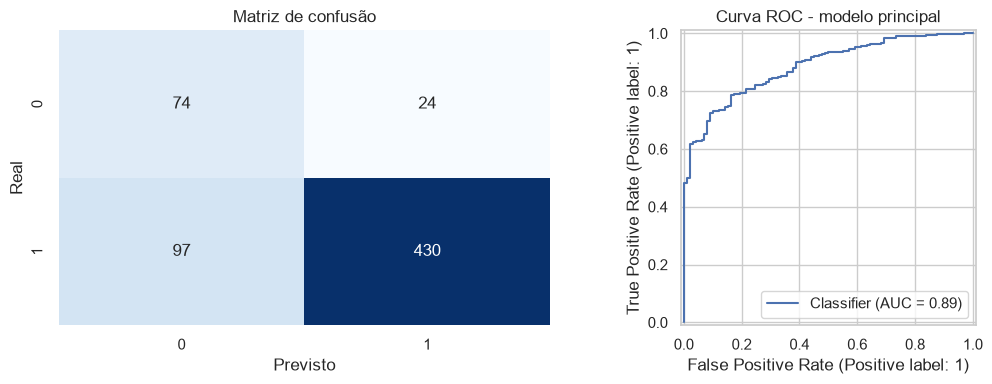

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="Matriz de confusão", xlabel="Previsto", ylabel="Real")
RocCurveDisplay.from_predictions(y.iloc[idx_teste], score, ax=axes[1])
axes[1].set_title("Curva ROC - modelo principal")
plt.tight_layout()
plt.show()

## Conclusão

O modelo inicial fica próximo do acaso. O sinal aumenta quando entram dados de logística e atendimento. O uso indicado é ranking e priorização de risco, não decisão automática nem probabilidade absoluta. Como a base não possui datas e horários dos eventos, uma implantação real precisa reconstruir a ordem dos eventos e validar o resultado em dados futuros.